In [1]:
# Bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy as sc
from scipy.optimize import curve_fit
from scipy.stats import linregress
from scipy.stats import chi2
from sklearn.metrics import r2_score
from scipy.optimize import minimize_scalar
import glob
import math
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle
import matplotlib.image as mpimg
from scipy.signal import find_peaks

import os

In [2]:
def chicuadrado(x,y, funcion, popt,sigmay):
  N = len(y)
  dof = N-len(popt)
  chi = 0
  for i in range(N):
    y_func = funcion(x, *popt)
    chi = chi + (y[i]-y_func[i])**2/(sigmay[i])**2
  chired=chi/dof
  return chi, chired
def lineal(x,m,b):
  return m*x+b

# Funciones para el análisis

In [3]:
def minimize(array, x):
    index = np.argmin(np.abs(array - x))
    return index, array[index]


# def select_element(E, I, element,tol):
#   """

#   E, I: listas de energía e intensidad

#   element: un string del símbolo del elemento que queremos

#   Busca los picos con find_peaks, y devuelve Las coordenadas X e Y del gráfico
#   de la medición donde se encuentra el elemento seleccionado.

#   """

#   # Encuentra los picos
#   p, peaks = sc.signal.find_peaks(I, height = 100, distance=18)

#   # Les asigna energías
#   energies = np.array([E[i] for i in p])

#   # En estas listas vamos a guardar las energías que corresponderían a las energías de los picos del elemento en cuestión
#   E_elem = []
#   I_elem = []
#   ind_elem = []

#   for e in ref[element]['Lines']:
#     #Para cada valor de energía del elemento, encuentro el pico más cercano
#     index, energy = minimize(energies, e)
#     if np.abs(energy-e)<tol: #Si el pico está más cerca de ese valor de energía que nuestra tolerancia, lo guardamos
#       E_elem.append(energy)
#       I_elem.append(peaks['peak_heights'][index])
#       ind_elem.append(np.argwhere(ref[element]['Lines']==e)[0][0])

#   return E_elem, I_elem, ind_elem
def select_element2(df, element):
  """

  df: un dataframe de Pandas, con 'Energy' e 'Intensity' sus dos entradas.

  element: la energía del elemento que queremos encontrar, dada en keV

  Busca los picos con find_peaks, y devuelve Las coordenadas X e Y del gráfico
  de la medición donde se encuentra el elemento seleccionado.

  """

  X = df['Energy']
  Y = df['Intensity']

  # Encuentra los picos
  p, peaks = sc.signal.find_peaks(Y, height = 100, distance=18)

  # Les asigna energías
  energies = np.array([X[i] for i in p])

  # Encuentra la más cercana
  index, energy = minimize(energies, element)

  coord = p[index]

  X_elem = X[coord]
  Y_elem = Y[coord]

  # Le agrego una tolerancia
  if np.abs(X_elem - element) < 0.4:
    return X_elem, Y_elem
  else:
    return np.nan, np.nan

def select_element(peaks, energies, element ,tol):
  """

  E, I: listas de energía e intensidad

  element: un string del símbolo del elemento que queremos

  Busca los picos con find_peaks, y devuelve Las coordenadas X e Y del gráfico
  de la medición donde se encuentra el elemento seleccionado.

  """

  # En estas listas vamos a guardar las energías que corresponderían a las energías de los picos del elemento en cuestión
  E_elem = []
  I_elem = []
  ind_elem = []

  for e in ref[element]['Lines']:
    #Para cada valor de energía del elemento, encuentro el pico más cercano
    index, energy = minimize(energies, e)
    if np.abs(energy-e)<tol: #Si el pico está más cerca de ese valor de energía que nuestra tolerancia, lo guardamos
      E_elem.append(energy)
      I_elem.append(peaks['peak_heights'][index])
      ind_elem.append(np.argwhere(ref[element]['Lines']==e)[0][0])
  I_max=I_elem[np.argmax(ref[element]['Lines'])]
  return E_elem, I_elem, ind_elem, I_max




In [14]:
#PCA
def PCA(df, elem_name):
  """
  df: dataframe con las proporciones de los elementos, cuyas filas son las mediciones y las columnas los elementos

  elem_name: lista de strings de los elementos
  """   
  for i in elem_name:
    #Normalizamos
    mean = np.mean(df[i])
    std = np.std(df[i])
    df[i] = (df[i] - mean)/std
  # Armamos la matriz de covarianzas
  cov_matrix = np.cov(np.transpose(df))
  # Buscamos autovectores y autovalores
  eigval1, eigvec1 = np.linalg.eigh(cov_matrix)
  # Ordenamos autovalores por módulo decreciente y los autovectores también
  eigval=sorted(eigval1, key=abs)
  eigval=eigval[::-1]
  eigvec=[]
  for i in range(len(eigvec1)):
      j=np.argwhere(eigval1==eigval[i])[0][0]
      v=eigvec1[:,j]
      eigvec.append(v)
  #La matriz de autovectores está traspuesta
  eigvec=np.array(eigvec)

  # Calculamos el principal component score para cada medición
  pc_score = np.transpose(np.matmul(eigvec , np.transpose(df)))
  # Calculamos la varianza acumulada
  exp_var = eigval/np.sum(eigval)
  cumulative_exp_var = []
  for i in range(len(eigval)):
    sum = 0
    for j in range (i+1):
      sum = sum + exp_var[j]
    cumulative_exp_var.append(sum)

  return eigval,eigvec, pc_score, cumulative_exp_var

# Calibración


[20.27961627 -1.07632353]


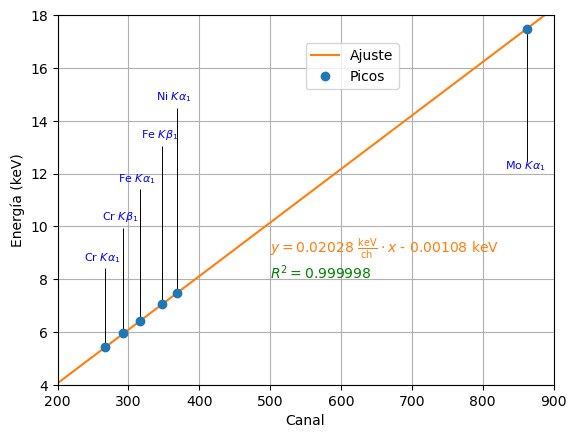

In [4]:
# Calibración

file="C:/Users/agusd/OneDrive/Escritorio/Facultad/Laboratorio 7/Calibracion 28082026/Cal 280826.csv"
dcal = pd.read_csv(file, skiprows=20)
ch=dcal['Channel#']
I=dcal['Intensity']
plt.plot(ch,I)
plt.xlabel('Canal')
plt.ylabel('Intensidad (cps)')

peaks, _=find_peaks(I,height=5000)

elem=['Cr', 'Fe', 'Mo', 'Mn', 'Ni']
plt.plot(ch,I)
plt.xlabel('Canal')
plt.ylabel('Intensidad (cps)')
for i in peaks:
  plt.plot(ch[i], I[i], marker='o', color='orange', markersize=5)

plt.xlim(0,peaks[-1]+10)


picos=[r'Cr $K\alpha_1$',r'Cr $K\beta_1$',r'Fe $K\alpha_1$',r'Fe $K\beta_1$',r'Ni $K\alpha_1$',r'Mo $K\alpha_1$']
s=[3,4,5,6,7,-5]
I_elem=[5.41,5.95, 6.4, 7.06, 7.48,17.48]
popt= np.polyfit(peaks, I_elem, 1)
plt.xlabel('Canal')
plt.ylabel('Energía (keV)')
X=np.linspace(200, 900,100)
plt.text(500, 8, r"$R^{2}=$"+str(np.round(r2_score(I_elem, lineal(peaks,*popt)),6)), color='green')
plt.text(500, 9, r"$y=$"+str(np.round(popt[0],5))+r" $\frac{\text{keV}}{\text{ch}}\cdot x$ - "+str(np.round(np.abs(popt[1]),5))+" keV", color='C1')
for i in range(len(picos)):
  plt.vlines(peaks[i],I_elem[i], I_elem[i]+s[i], color='black', linewidth=0.7)
  plt.text(peaks[i]-30,I_elem[i]+s[i]+(s[i]/np.abs(s[i]))*0.3, picos[i], color='blue', fontsize= 8)
plt.plot(X,lineal(X,*popt), label='Ajuste', color='C1')
plt.plot(peaks,I_elem,'o', label='Picos', color='C0')
plt.xlim(200,900)
plt.ylim(4,18)
plt.legend(loc=(.5,.8))
plt.grid()
plt.savefig("calibracion.pdf", format="pdf", bbox_inches="tight")
print(1000*popt)



def calib(x):
  m , b=popt
  return x*m + b

#Carga Google Drive
# from google.colab import drive
# drive.mount('/content/drive')

# Carga de líneas

In [5]:
"""

Agus: si querés correr este código, basta con cambiar 'path' a
tu ubicación personal de la carpeta de Materia. Lo demás debería
andar igual.

No te olvides de conectar a Drive.

"""

path = "G:/.shortcut-targets-by-id/1lq8dkZkDfQ44V5t618RlM1yQQ0FrC0Ix/Lab 6y7 - MATERIA_/"

cols = [0, 1, 2, 3, 4]
i = 7
while i < 75:
  cols.append(i)
  cols.append(i+1)
  i = i+4
cols.append(75)
# cols.append(76)

raw_ref = pd.read_csv(path + '/Otros archivos/tabla lineas.csv', skiprows=1,usecols=cols)
# Dadas las intensidades, si dividimos por 100 queda normalizado


clr = pd.read_csv(path + '/Otros archivos/Colors.csv')
colors=clr['Color']

ref = {}

for i in range(len(raw_ref)): #Itero sobre todos los elementos
  A = raw_ref[raw_ref['Atomic#']==i+1] #selecciono la fila del i-ésimo elemento
  symbol = raw_ref['Symbol'][i] #guardo su símbolo
  # color = raw_ref['Color'][i]
  lines = []
  intensity = []
  color=colors[i]
  j = 4
  while j < 40:
    lines.append(A.iloc[:, j][i])
    intensity.append(A.iloc[:, j+1][i])
    j = j + 2

  d = pd.DataFrame({'Lines' : lines , 'Intensity' : intensity, 'Color' : color})

  ref[symbol] = d

  del A

#Creo lista de elementos
elements= [str(elem) for elem in raw_ref['Symbol']]
print(elements)

['H', 'He', 'Li', 'Be', 'B', 'C', 'N', 'O', 'F', 'Ne', 'Na', 'Mg', 'Al', 'Si', 'P', 'S', 'Cl', 'Ar', 'K', 'Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn', 'Ga', 'Ge', 'As', 'Se', 'Br', 'Kr', 'Rb', 'Sr', 'Y', 'Zr', 'Nb', 'Mo', 'Tc', 'Ru', 'Rh', 'Pd', 'Ag', 'Cd', 'In', 'Sn', 'Sb', 'Te', 'I', 'Xe', 'Cs', 'Ba', 'La', 'Ce', 'Pr', 'Nd', 'Pm', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Ho', 'Er', 'Tm', 'Yb', 'Lu', 'Hf', 'Ta', 'W', 'Re', 'Os', 'Ir', 'Pt', 'Au', 'Hg', 'Tl', 'Pb', 'Bi', 'Po', 'At', 'Rn', 'Fr', 'Ra', 'Ac', 'Th', 'Pa', 'U', 'Np', 'Pu', 'Am', 'Cm']


# Carga de datos

In [6]:
data = {}
names=[]
for file in glob.glob(path+"Mediciones/Ocres/*.*"):
  if os.path.basename(file)[-1]=='v':
    name=os.path.splitext(os.path.basename(file))[0].split(".")[0]
    names.append(name)
    df = pd.read_csv(file, skiprows=20)
    e=calib(df['Channel#'])
    I=df['Intensity']
    d= pd.DataFrame({'Energy' : e, 'Intensity' : I})
    data[name]=d

names=sorted(names, key=lambda x: (
        int(x.split()[0][3:]),  # primer número
        int(x.split()[1])       # segundo número
    ))
print(names)

['OPL1 1', 'OPL1 2', 'OPL2 1', 'OPL2 2', 'OPL2 3', 'OPL2 4', 'OPL3 1', 'OPL3 2', 'OPL4 1', 'OPL5 1', 'OPL5 2', 'OPL5 3', 'OPL6 1', 'OPL7 1', 'OPL7 2', 'OPL8 1', 'OPL8 2', 'OPL8 3', 'OPL9 1', 'OPL10 1', 'OPL10 2', 'OPL11 1', 'OPL12 1', 'OPL12 2']


# Análisis

In [ ]:
fig, ax = plt.subplots(len(names),1,figsize=(8,len(names)*6),tight_layout=True,dpi=300, sharey=False)
elem=['Pb','Fe','As', 'Ca', 'Ti', 'Cu', 'Ni', 'Zn', 'Nb', 'Mn','Sr', 'Br', 'Cr', 'Zr', 'Kr']
# elem.append('Rh')
# , 'Ru', 'Sc', 'K', 'Co', 'Ar', 'Kr']
# colors=['gold','green','orange','skyblue','gray','chocolate','magenta','darkgray','red', 'salmon']

for i in range(len(names)):
  #Encuentra los picos
  p, peaks = sc.signal.find_peaks(data[names[i]]['Intensity'], height = 100, distance=18)

  # Les asigna energías
  energies = np.array([data[names[i]]['Energy'][j] for j in p])

  E_Rh, I_Rh, ind_Rh, _= select_element(peaks, energies,'Rh',0.7)
  for el in elem:
    E_el, I_el, ind_el, _= select_element(peaks, energies,el,0.7)
    for j, k in enumerate(ind_el):
      if not j:
       ax[i].vlines(ref[el]['Lines'][k], 0, ref[el]['Intensity'][k]/100*np.max(data[names[i]]['Intensity'])/I_Rh[-1], color=ref[el]['Color'][0], label=el)
      else:
        ax[i].vlines(ref[el]['Lines'][k], 0, ref[el]['Intensity'][k]/100*np.max(data[names[i]]['Intensity'])/I_Rh[-1], color=ref[el]['Color'][0])
  ax[i].semilogy(data[names[i]]['Energy'],data[names[i]]['Intensity']/I_Rh[-1], label='Espectro',color='black')
  ax[i].set(xlabel='Energía (keV)',ylabel='I (normalizado)',title=names[i])
  ax[i].grid()
  ax[i].set_xlim(2.5, 22.5)
  ax[i].set_ylim(.1, 10**math.ceil(np.log(np.max(data[names[i]]['Intensity'])/I_Rh[-1])/np.log(10)))
  ax[i].legend(loc=(1,.3), prop={'size':8})


IndexError: list index out of range

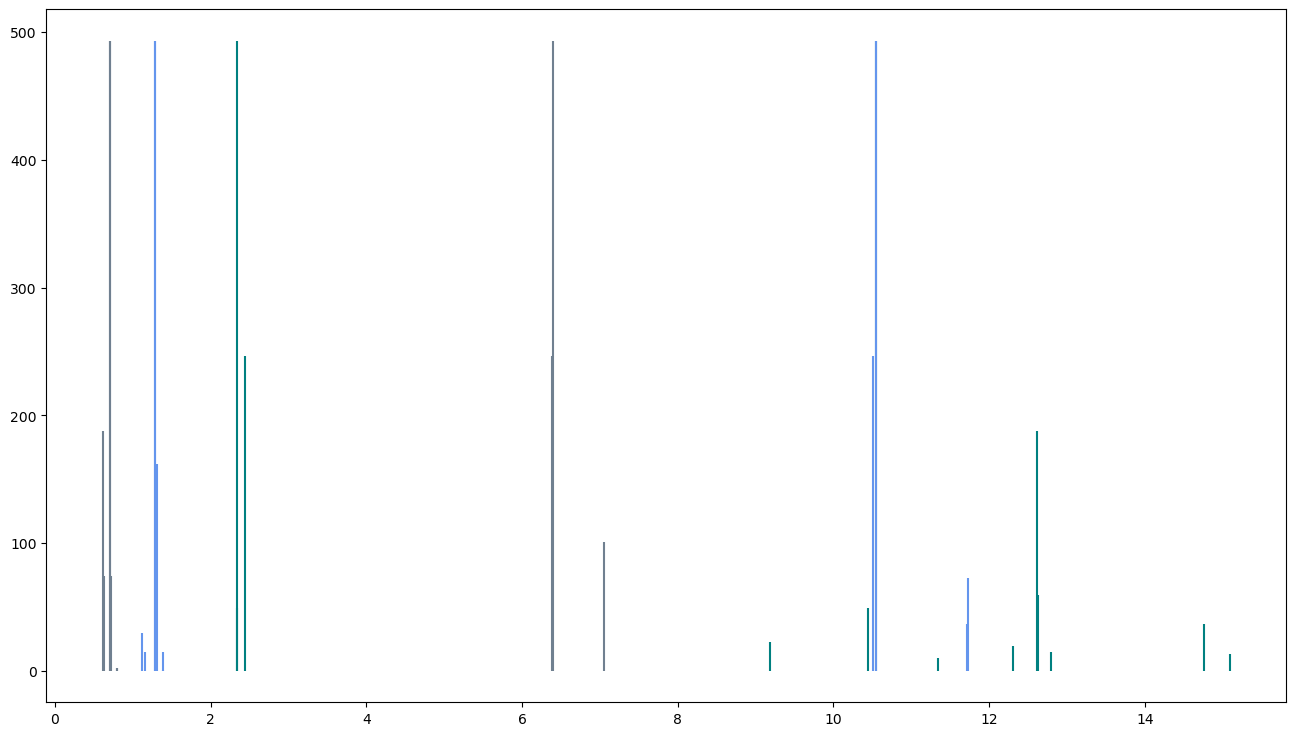

In [42]:
elem=['Pb','Fe','As', 'Ca', 'Ti', 'Cu', 'Ni', 'Zn', 'Mn','Sr','Rb','Cr', 'Zr', 'K', 'P', 'Tl']
elem.append('Rh')
# , 'Ru', 'Sc', 'K', 'Co', 'Ar', 'Kr']
# colors=['gold','green','orange','skyblue','gray','chocolate','magenta','darkgray','red', 'salmon']
int_lines = {}
lines = {}
for i in range(len(names)):
  #Encuentra los picos
  p, peaks = sc.signal.find_peaks(data[names[i]]['Intensity'], height = 100, distance=18)

  # Les asigna energías
  energies = np.array([data[names[i]]['Energy'][j] for j in p])
  E_Rh, I_Rh, ind_Rh,_= select_element(peaks, energies,'Rh',0.7)
  Int=[]
  Line=[]
  plt.figure(figsize=(16,9))
  for el in elem:
    E_el, I_el, ind_el,I_max= select_element(peaks, energies,el,0.7)
    I= I_max/I_Rh[-1]
    E= E_el[np.argwhere(I_el ==I_max)[0][0]]
    Int.append(I)
    Line.append(E)
    for j, k in enumerate(ind_el):
      if not j:
       plt.vlines(ref[el]['Lines'][k], 0, ref[el]['Intensity'][k]/100*np.max(data[names[i]]['Intensity'])/I_Rh[0], color=ref[el]['Color'][0], label=el)
    #    plt.text(ref[el]['Lines'][k], ref[el]['Intensity'][k]/100*np.max(data[names[i]]['Intensity'])/I_Rh[0]+50,str(ref[el]['Lines'][k]),color=ref[el]['Color'][0])      
      else:
        plt.vlines(ref[el]['Lines'][k], 0, ref[el]['Intensity'][k]/100*np.max(data[names[i]]['Intensity'])/I_Rh[0], color=ref[el]['Color'][0])
        # plt.text(ref[el]['Lines'][k], ref[el]['Intensity'][k]/100*np.max(data[names[i]]['Intensity'])/I_Rh[0]+50,str(ref[el]['Lines'][k]),color=ref[el]['Color'][0]) 
  Int=np.array(Int)
  Line=np.array(Line)
  int_lines[names[i]]=Int
  lines[names[i]]=Line
  plt.semilogy(data[names[i]]['Energy'],data[names[i]]['Intensity']/I_Rh[0], label='Espectro',color='black')
  plt.gca().set(xlabel='Energía (keV)',ylabel='I (normalizado)',title=names[i])
  plt.grid()
  plt.xlim(2.5, 22.5)
  plt.ylim(0.1, np.max(data[names[i]]['Intensity'])/I_Rh[0]+50)
  plt.legend(ncols=1,loc=(1,.3), prop={'size':8})
  plt.savefig("analisis"+names[i]+".pdf", format="pdf", bbox_inches="tight")
  plt.close()


In [ ]:
# for name in names:
#     plt.rcParams["font.size"] = 16
#     plt.tight_layout()
#     x = np.arange(len(elem))
#     fig, ax = plt.subplots(1, 1, figsize=(len(elem)*1,4))
#     ax.bar(x, int_lines[name], width=0.4, color='green', align='center')
#     ax.set_xticks(x, elem, size='small')

#     plt.title(name)
#     plt.ylabel('Intesidad (norm. Rh)')
#     # plt.legend()
#     plt.grid()
#     plt.savefig('barras'+name+'.pdf', format='pdf')
#     plt.close()

# # 

<Figure size 640x480 with 0 Axes>

In [34]:
df_lines= pd.DataFrame(int_lines, index=elem)
df_lines=df_lines.T
df_lines

,Pb,Fe,As,Ca,Ti,Cu,Ni,Zn,Mn,Sr,Rb,Cr,Zr,K,P,Tl,Rh
OPL1 1,10.788889,1103.350000,1.000000,14.600000,5.555556,12.150000,12.150000,4.716667,1103.350000,1.094444,3.605556,4.300000,1.433333,14.600000,1.433333,1.433333,2.438889
OPL1 2,3.747875,588.368272,0.657224,12.631728,3.062323,7.526912,7.526912,3.130312,588.368272,1.005666,1.512748,2.900850,1.000000,12.631728,1.000000,1.005666,1.968839
OPL2 1,2.791193,102.296875,2.926136,285.592330,4.688920,3.181818,4.877841,3.181818,102.296875,7.034091,6.460227,2.650568,6.460227,285.592330,6.460227,7.034091,6.166193
OPL2 2,2.209705,244.682842,2.246101,345.384749,2.814558,1.987868,4.136915,2.892548,244.682842,7.249567,7.249567,2.270364,7.249567,345.384749,7.249567,7.249567,4.597920
OPL2 3,1.678035,132.754434,1.639836,290.282401,2.189632,2.991814,3.549795,2.991814,132.754434,6.124147,6.124147,1.376535,6.124147,290.282401,6.124147,6.124147,3.462483
OPL2 4,1.933216,124.065026,1.933216,353.318102,2.073814,1.931459,4.144112,2.625659,124.065026,7.256591,7.256591,2.066784,7.256591,353.318102,7.256591,7.256591,4.117750
OPL3 1,9.125131,74.377487,9.125131,43.195812,5.242932,9.203141,7.692670,9.203141,74.377487,5.112042,4.524607,2.740314,3.445026,43.195812,1.561780,9.203141,4.330366
OPL3 2,8.463520,56.848929,8.463520,30.691619,2.665039,6.158394,5.318145,6.158394,56.848929,3.474369,2.987524,1.547328,2.305940,30.691619,1.000000,8.463520,2.045837
OPL4 1,4.492308,549.148718,4.492308,55.384615,21.612821,32.907692,32.907692,12.056410,549.148718,7.425641,6.397436,12.638462,6.397436,55.384615,6.397436,12.056410,27.315385
OPL5 1,3.677419,578.139785,2.752688,56.809140,20.185484,2.553763,4.677419,2.373656,578.139785,8.688172,4.895161,5.422043,8.688172,56.809140,4.459677,5.018817,20.422043


# PCA

## Masajeo de datos

In [7]:
# Los picos que vamos a usar para identificar cada elemento, y algunos secundarios para tener de referencia
# Todo está en keV
Pb = 10.551
Pb2 = 12.614
Hg = 9.989
Fe = 6.405
Fe2 = 7.059
Ca = 3.692
Ti = 4.512
Cu = 8.046
Ni = 7.48
Zn = 8.637
Zn2 = 9.57
Rh = 20.216
As = 10.543
Sr = 14.165
Mn = 5.900
Fe_bis = Fe*2
Zr = 15.775
Rb = 13.396
K = 3.314

In [21]:
# Picos de elementos

elem=[Fe, Fe2, Ca, Ti, Cu, Zn, Sr, Mn, Fe_bis, Zr, Rb, K]
elem_name=['Fe', 'Fe2', 'Ca', 'Ti', 'Cu', 'Zn', 'Sr', 'Mn']

I_elem = {}

for i in range(len(elem_name)):
  I = []

  for j in names:

    # Busco el rodio para normalizar
    X_Rh, Y_Rh = select_element2(data[j], Rh)

    # Selecciono las coordenadas del pico del elemento buscado
    X, Y = select_element2(data[j], elem[i])
    # Guardo la inensidad normalizada
    I.append(Y/Y_Rh)

  # Añado las intensidades al diccionario, con clave símbolo del elemento
  I_elem[elem_name[i]] = I

df_pca = pd.DataFrame(I_elem, index=names)

df_pca

,Fe,Fe2,Ca,Ti,Cu,Zn,Sr,Mn
OPL1 1,694.416084,102.944056,9.188811,3.496503,7.646853,2.968531,0.688811,2.706294
OPL1 2,493.334917,74.840855,10.591449,2.567696,6.311164,2.624703,0.843230,2.432304
OPL2 1,21.113163,3.481970,58.943712,0.967751,0.561419,0.656699,1.451774,0.547054
OPL2 2,53.215982,7.398417,75.117603,0.612137,0.432341,0.629099,1.228044,0.493781
OPL2 3,38.340820,5.344760,83.836485,0.632388,0.493302,0.864066,1.212766,0.397557
OPL2 4,30.129321,4.321383,85.803671,0.503628,0.469057,0.637644,1.172429,0.501921
OPL3 1,26.469350,4.790199,15.372461,1.865847,2.420160,3.275200,1.819266,0.975219
OPL3 2,27.787618,4.925361,15.001989,1.302665,2.228424,3.010208,1.698263,0.756330
OPL4 1,179.070234,27.862040,18.060201,7.047659,10.730769,3.931438,2.421405,4.121237
OPL5 1,113.852832,18.030704,11.187401,3.975119,0.502912,0.463737,0.988354,1.067761


## Cálculo de componentes principales

In [22]:
eigval,eigvec,pc_score, cumulative_exp_var=PCA(df_pca, elem_name)

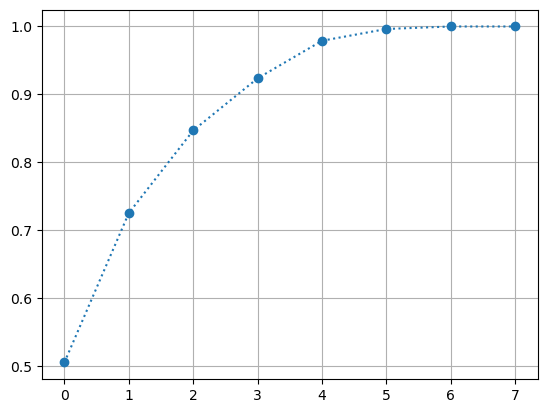

In [24]:
plt.plot(np.arange(len(eigval)), cumulative_exp_var,'o', ls=':')
plt.grid()

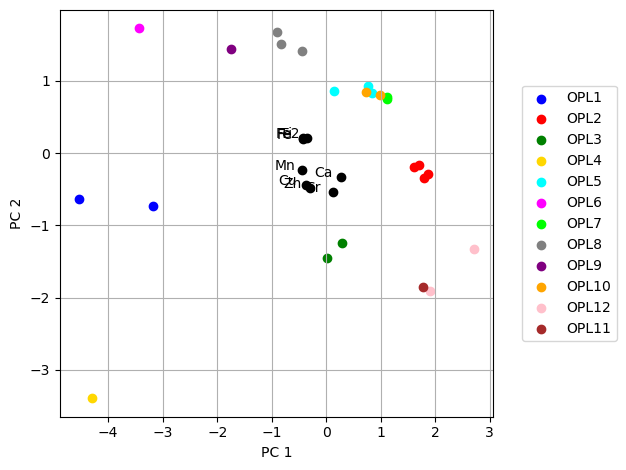

In [25]:
pc_scores = pd.DataFrame(pc_score)
plt.scatter(pc_scores.iloc[0:2][0], pc_scores.iloc[0:2][1], label='OPL1', c='blue')
plt.scatter(pc_scores.iloc[2:6][0], pc_scores.iloc[2:6][1], label='OPL2', c='red')
plt.scatter(pc_scores.iloc[6:8][0], pc_scores.iloc[6:8][1], label='OPL3', c='green')
plt.scatter(pc_scores.iloc[8:9][0], pc_scores.iloc[8:9][1], label='OPL4', c='gold')
plt.scatter(pc_scores.iloc[9:12][0], pc_scores.iloc[9:12][1], label='OPL5', c='cyan')
plt.scatter(pc_scores.iloc[12:13][0], pc_scores.iloc[12:13][1], label='OPL6', c='magenta')
plt.scatter(pc_scores.iloc[13:15][0], pc_scores.iloc[13:15][1], label='OPL7', c='lime')
plt.scatter(pc_scores.iloc[15:18][0], pc_scores.iloc[15:18][1], label='OPL8', c='gray')
plt.scatter(pc_scores.iloc[18:19][0], pc_scores.iloc[18:19][1], label='OPL9', c='purple')
plt.scatter(pc_scores.iloc[19:21][0], pc_scores.iloc[19:21][1], label='OPL10', c='orange')
plt.scatter(pc_scores.iloc[21:23][0], pc_scores.iloc[21:23][1], label='OPL12', c='pink')
plt.scatter(pc_scores.iloc[23:24][0], pc_scores.iloc[23:24][1], label='OPL11', c='brown')

for i in range(len(elem_name)):
  plt.scatter(eigvec[0,i], eigvec[1,i], color='black')
  plt.text(eigvec[0,i]-0.5, eigvec[1,i], elem_name[i], color='black')

plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.grid()
plt.legend(bbox_to_anchor=(1.05, 0.5), loc='center left')
plt.tight_layout()